# Pandas
Pandas viene usata per la lettura ed elaborazione dei dati provenienti da sorgenti di vario tipo, come ad esempio file CSV o Excel, ma anche file di testo e database.



In [2]:
%pip install pandas

import pandas as pd
import numpy as np

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.9 MB 24.5 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.9 MB 33.2 MB/s eta 0:00:01
   ---------------------------------------- 9.9/9.9 MB 30.1 MB/s  0:00:00

   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   ---------------------------------------- 0/2 [tzdata]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   -------------------- ------------------- 1/2 [pandas]
   ---------------

Pandas gestisce prevalentemente dati strutturati sotto forma tabellare, ossia simili a quelli comunemente contenuti all'interno dei fogli di calcolo o nei database. Questi dati sono sicuramente tra i più diffusi ed utilizzati nel contesto dell'analisi dei dati, ovviamente escludendo le immagini: in tal senso, per modellarli, Pandas ci mette a disposizione un'apposita struttura denominata DataFrame.

I dataframe sono quindi delle strutture atte a contenere dati di ogni tipo. Questi sono normalmente organizzati in righe e colonne, in maniera del tutto analoga a quella in cui sono organizzati i fogli di calcolo ed i database. Importante anche sottolineare come, per convenzione, le singole righe rappresentino i campioni del dataset, mentre le colonne siano associati ai valori assunti dalle diverse caratteristiche, o feature, di ciascun campione.

Facciamo un esempio usando il dataset Titanic, che è uno tra i più utilizzati a scopi di sperimentazione. Per prima cosa, generiamo un dataframe rappresentativo dei dati contenuti nel dataset, leggendo il file titanic.csv, che possiamo scaricare a questo link. 

https://python.angelocardellicchio.it/material/data/titanic.csv
salvate questo file nella cartella dello script

Per leggere i dati, dovremo utilizzare il metodo read_csv(), cui passeremo il percorso relativo del file:


In [7]:
df = pd.read_csv('titanic.csv')

In [ ]:
# Usiamo il metodo head() per mostrare a schermo le prime cinque righe del dataframe.

df.head() #prime 5 di defoult altrimenti specifica

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Vediamo rapidamente che ad ogni passeggero sono associate delle feature, di cui possiamo inferire il tipo (lo verificheremo a breve):
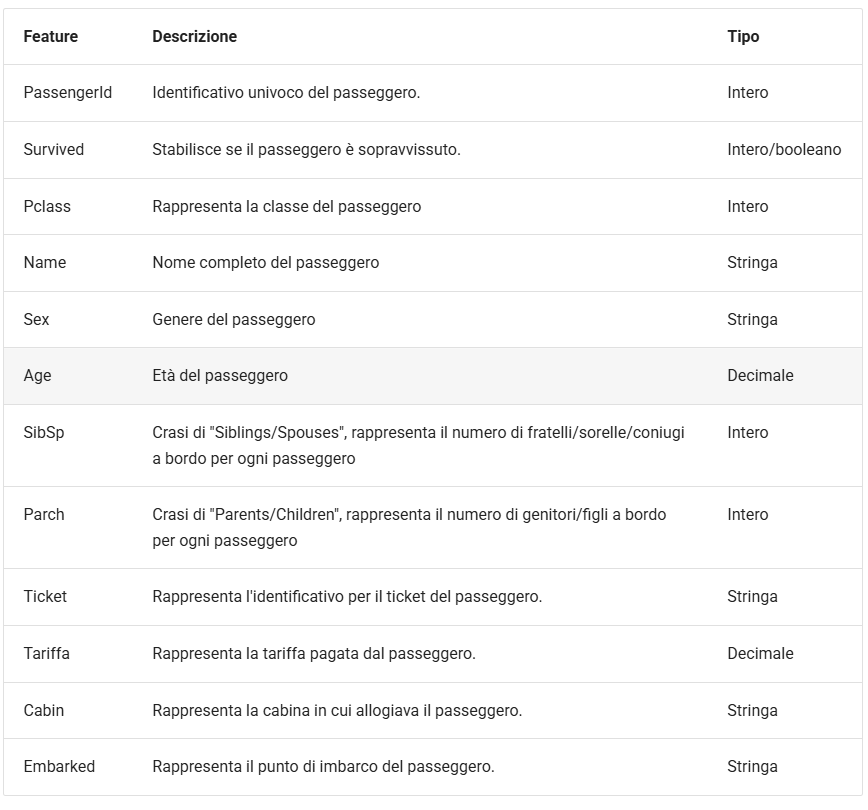

Verifichiamo che le nostre ipotesi sul tipo di dato siano corrette; per farlo, possiamo usare la proprietà dtypes del dataframe:

In [9]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Notiamo subito la presenza di tre tipi di colonna, ovvero int64, float64 e object. Laddove i primi due sono autoesplicativi, merita una particolare menzione il tipo object, che viene associato automaticamente a tutte le stringhe.

Normalmente, usare il tipo object comporta diversi problemi nella successiva fase di analisi dei dati. Potrebbe quindi essere una buona idea parametrizzare la funzione read_csv() mediante il parametro dtype, che accetta un dizionario che specifica il tipo di una o più colonne. Ad esempio, se volessimo specificare che i nomi sono delle stringhe, potremmo usare il tipo string:

In [11]:
types = {'Name': 'string'}
df = pd.read_csv('titanic.csv', dtype=types)
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            string
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

## Series

Abbiamo visto come ogni DataFrame sia in realtà composto da diverse colonne, ciascuna rappresentativa di una feature specifica. Nella pratica, Pandas ci offre un modo per estrarre singolarmente ciascuna di queste colonne mediante la classe Series. Ad esempio, potremmo estrarre la serie relativa agli identificativi numerici dei passeggeri:


In [12]:
names = df['Name']
names.head()

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
Name: Name, dtype: string

### Accesso agli elementi di una serie¶
Possiamo accedere ad un singolo elemento di una serie mediante una classica procedura di indicizzazione. Notiamo infatti come ogni campione all'interno della serie sia associato ad un indice numerico crescente il cui valore iniziale è pari a 0; pertanto, possiamo accedere all'
i
i-mo elemento della serie richiamando l'
i
−
1
i−1-mo indice, esattamente come accade per le liste o le sequenze.

In [13]:
names[0]

'Braund, Mr. Owen Harris'

### Accesso agli elementi del dataframe¶
L'accesso agli elementi del dataframe può avvenire attraverso diverse modalità. In primo luogo, possiamo accedere allo specifico valore di una feature di un dato campione mediante il chained indexing:

In [14]:
df['Age'][1]

np.float64(38.0)

In [53]:
## standard and safe
print (df['Age'],'\n')

## equivalent but dangerous (imagine blank spaces in the name of the column..)
print (df.Age)

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64 

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64


In [55]:
# selecting rows by counting
print (df[0:3])


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  


In alternativa, è possibile usare la funzione loc(row_idx, col) che, se chiamata su un oggetto di tipo DataFrame, ci permette di accedere al valore assunto dalla feature col per l'elemento in posizione row_idx:

In [57]:
# getting a cross section (part of the DataFrame) using a label
df.loc[0]

PassengerId                          1
Survived                             0
Pclass                               3
Name           Braund, Mr. Owen Harris
Sex                               male
Age                               22.0
SibSp                                1
Parch                                0
Ticket                       A/5 21171
Fare                              7.25
Cabin                              NaN
Embarked                             S
Name: 0, dtype: object

In [58]:
df.loc[1, ('Age')]

np.float64(38.0)

In [17]:
# La funzione loc() può operare anche su delle slice di dati:
df.loc[1:5, ('Age')]

1    38.0
2    26.0
3    35.0
4    35.0
5     NaN
Name: Age, dtype: float64

In [18]:
# o su insiemi di feature:
df.loc[1:5, ('Age', 'Sex')]

,Age,Sex
1,38.0,female
2,26.0,female
3,35.0,female
4,35.0,male
5,NaN,male


Sottolineamo che la funzione loc() opera sugli indici di riga. In questo caso, il nostro dataframe ha degli indici di riga interi, assegnati automaticamente in fase di lettura del dataframe. 

NB: Nel caso decidessimo di usare una colonna del dataframe come indice, potremmo usare il metodo set_index(): df = df.set_index('Ticket')

In [20]:
df.iloc[2:5, 2:4]

,Pclass,Name
Ticket,,
STON/O2. 3101282,3,"Heikkinen, Miss. Laina"
113803,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
373450,3,"Allen, Mr. William Henry"


In [52]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

### Maschere booleane¶
Supponiamo di voler selezionare soltanto gli uomini maggiorenni presenti nel dataset del Titanic. Per farlo, possiamo usare un'istruzione che implementi delle logiche di tipo booleano:

In [21]:
men = df[(df['Age'] > 18) & (df['Sex'] == 'male')]
men.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
Ticket,,,,,,,,,,,
A/5 21171,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,NaN,S
373450,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,NaN,S
17463,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,51.8625,E46,S
A/5. 2151,13,0,3,"Saundercock, Mr. William Henry",male,20.0,0,0,8.0500,NaN,S
347082,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,31.2750,NaN,S


Nella pratica, stiamo filtrando il dataset in base all'AND logico tra due condizioni:

- df['Age'] > 18: questa condizione genera una maschera booleana che è True soltanto se l'età per quel passeggero è maggiore di 18 anni;
- df['Sex'] == 'male': questa condizione genera una maschera booleana che è vera soltanto se il genere del passeggero è maschile.

### La funzione groupby¶
Possiamo sfruttare la funzione groupby per raggruppare insiemi di dati (normalmente pertinenti a categorie).

Ad esempio, potremmo raggruppare i passeggeri per genere:

In [22]:
df.groupby(['Sex'])

Possiamo ovviamente estrarre delle statistiche a partire da questi raggruppamenti. Vediamo, ad esempio, l'età media dei passeggeri di sesso femminile e maschile:

In [23]:
df.groupby(['Sex'])['Age'].mean()

Sex
female    27.915709
male      30.726645
Name: Age, dtype: float64

In [50]:
# Series can be created from python dictionary too.
# Not that the elements can be whatever!
d = {'b' : 1, 'a' : 'cat', 'c' : [2,3]}
pd.Series(d)

b         1
a       cat
c    [2, 3]
dtype: object

## I/O in Pandas

### Lettura di dati da sorgenti eterogenee¶
Nel nostro primo esempio abbiamo usato la funzione read_csv per creare un dataframe partendo dai dati memorizzati in un file in formato CSV. Tuttavia, Pandas supporta molti altri formati.

Ad esempio, potremmo provare a leggere un file Excel:

Per leggere (e scrivere) da (su) Excel è necessario installare la libreria openpyxl (pip install openpyxl).

In [ ]:
df = pd.read_excel('dati.xlsx')

In alternativa, può essere letto un file in formato JSON, oppure ancora direttamente un database:
df = pd.read_json('dati.json')
df = pd.read_sql(SQL_QUERY)

Esiste un elenco completo delle (numerose) funzioni disponibili, che possono essere individuate sulla reference. In generale, comunque, la sintassi è sempre read_*(data_source), con * da sostituire con il tipo di sorgente dati (csv, excel, etc.).

### Scrittura di dati su destinazioni eterogenee¶
Possiamo anche scrivere un dataframe su file mediante le funzioni duali alle read_, che usano il suffisso to_ seguito dall'estensione del file destinazione. Ad esempio, potremmo scrivere un file CSV con il metodo to_csv:

In [ ]:
df.to_csv('train.xlsx')

### Aggiunta di feature e dati¶
Immaginiamo adesso di voler aggiungere una nuova feature ad un dataframe già esistente. Per farlo, iniziamo creando un dataframe da zero:

In [ ]:
df = pd.DataFrame([1,2,3,4,5], columns=['one'])
print(df)

#  Una lista 1D (tipo [1,2,3,4,5]) in pandas viene interpretata come una colonna.

   one
0    1
1    2
2    3
3    4
4    5


Possiamo aggiungere una nuova colonna semplicemente usando l'operatore di assegnazione e specificandone il nome:

In [29]:
df['two'] = df['one'] * 2
print(df)

   one  two
0    1    2
1    2    4
2    3    6
3    4    8
4    5   10


Possiamo poi inserire nuovi campioni in coda al dataframe. Per farlo, dovremo prima creare un nuovo dataframe dalle dimensioni coerenti con quello già esistente, e poi usare la funzione concat():

In [ ]:
df_add = pd.DataFrame([[6,7]], columns=['one', 'two'])
df = pd.concat([df, df_add])

Notiamo che la funzione concat() accetta, tra gli altri, il parametro axis. Se questo è uguale a zero (come lo è di default), la concat() effettua la concatenazione per righe; se è pari ad 1, invece, la concatenazione avviene per colonne. Tuttavia, è importante sottolineare come la concatenazione avvenga anche nel caso le misure non siano completamente coerenti: infatti, se provassimo ad effettuare una concatenazione per colonne, avremmo un risultato del tipo:

In [ ]:
pd.concat([df, df_add], axis=1)

I valori relativi alle righe con indice che va da 1 a 4, che ovviamente non saranno presenti, saranno automaticamente impostati a NaN, acronimo di Not a Number.

##  Manipolazione dei DataFrame

### Visualizzazione dei DataFrame¶
Pandas ci offre un supporto nativo a Matplotlib per permettere la visualizzazione dei dati contenuti all'interno di un dataframe.

In tal senso, possiamo usare la funzione plot() su una serie o su un intero dataframe; ad esempio, potremmo plottare le età dei passeggeri:

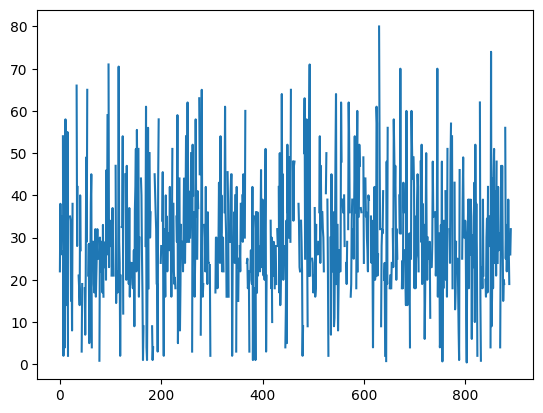

In [46]:
import matplotlib as plt
import matplotlib.pyplot as plt

df = pd.read_csv('titanic.csv')

df['Age'].plot()
plt.show()

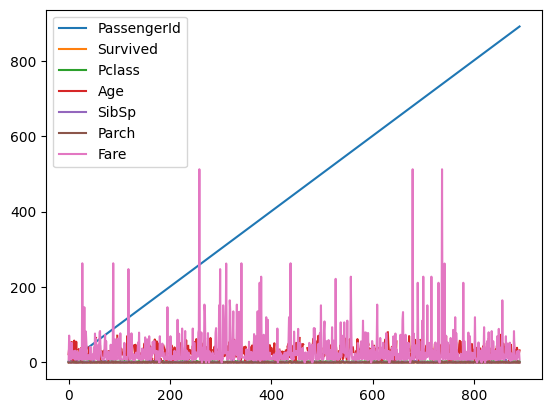

In [47]:
# Possiamo anche fare il plot dell'intero DataFrame:
df.plot()
plt.show()

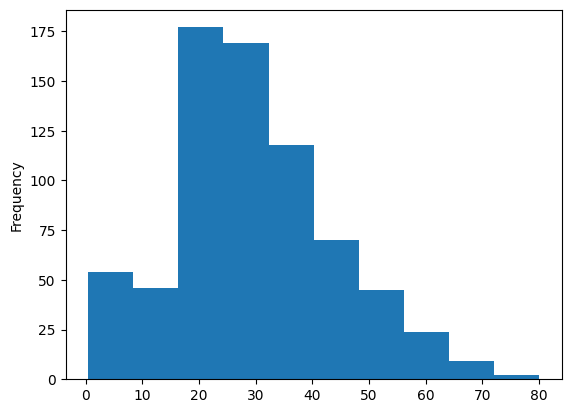

In [48]:
# Ovviamente, è possibile usare Pandas anche per fare il plot di altri tipi di grafico, come ad esempio gli istogrammi. Per farlo, si usano le apposite sotto-funzioni di plot:
df['Age'].plot.hist()
plt.show()

## Gestione dei valori mancanti¶
Ad esempio, riprendiamo le prime sei righe del dataset Titanic:

Notiamo come, per la feature Cabin, sia associato ai passeggeri 1, 3, 5 e 6 il valore NaN, così come per il parametro Age del passeggero 6. Questo indica che, nel dataset originario, il valore corrispondente risulta essere assente: NaN, infatti, è un acronimo che sta per Not a Number, e viene per convenzione utilizzato come placeholder per tutte le feature di cui non è possibile leggere il valore a partire dal dataset iniziale.

La presenza (o, per meglio dire assenza) di questi valori comporta l'impossibilità di utilizzare alcuni degli algoritmi che vedremo successivamente, in quanto questi prevedono la valorizzazione integrale di ciascun campione presente nel dataset. Per ovviare a questa problematica, Pandas ci mette a disposizione principalmente due alternative.

#### Opzione 1: rimozione dei dati mancanti¶
La prima alternativa offerta da Pandas sta nella rimozione dei dati mancanti usando la funzione dropna(), che ci permette di eliminare i campioni o le feature dove sono presenti valori mancanti.

In particolare, per eliminare i campioni che presentano dei valori mancanti, dovremo impostare il parametro axis a 0 (e, quindi, lavorare sulle righe):

In [49]:
df.dropna(axis=0)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
10,11,1,3,"Sandstrom, Miss. Marguerite Rut",female,4.0,1,1,PP 9549,16.7000,G6,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S
...,...,...,...,...,...,...,...,...,...,...,...,...
871,872,1,1,"Beckwith, Mrs. Richard Leonard (Sallie Monypeny)",female,47.0,1,1,11751,52.5542,D35,S
872,873,0,1,"Carlsson, Mr. Frans Olof",male,33.0,0,0,695,5.0000,B51 B53 B55,S
879,880,1,1,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",female,56.0,0,1,11767,83.1583,C50,C
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S


Per eliminare invece una feature che presenta uno o più dati mancanti nella sua interezza, agiamo per colonne, impostando axis=1:

In [ ]:
df.dropna(axis=1)

Eliminare interamente un campione (o addirittura una feature) per la presenza di un unico valore mancante potrebbe risultare una misura draconiana. Per evitare di far questo, possiamo decidere di impostare il parametro how ad all, nel qual caso il campione/feature sarà eliminato solo se tutti i valori risultano essere mancanti:
- df.dropna(axis=1, how='all')

In alternativa, possiamo impostare il parametro thresh, che ci permette di impostare una soglia minima di valori mancanti per eliminare il campione o la feature. Ad esempio, se volessimo eliminare tutte quelle feature che presentano almeno il 
50
%
50% di valori mancanti, dovremmo scrivere:
- df.dropna(axis=1, thresh=0.5)

#### Opzione 2: riempimento dei dati mancanti¶
L'altra opzione messa a disposizione da Pandas è quella del riempimento dei dati mancanti. Questa strada è percorribile usando la funzione fillna().

Nell'interpretazione base, possiamo usare fillna() parametrizzandolo con il valore che vogliamo utilizzare. Ad esempio:

In [ ]:
df.fillna(0) 
# In questo caso, andremo ad associare il valore 0 a tutti i NaN. 

## Operazioni statistiche sui dataframe¶
Pandas ci mette a disposizione delle funzioni, simili a quelle offerte da NumPy, per calcolare delle statistiche per ciascuna delle colonne presenti in un DataFrame. Ad esempio, possiamo calcolare la media usando la funzione mean():

In [ ]:
df.mean()

Ovviamente, esistono funzioni anche per calcolare varianza (var()), mediana (median()), deviazione standard (std()), e via discorrendo.

Particolarmente interessante è la funzione describe(), che ci mosta tutte le statistiche più significative per ognuna delle feature considerate.

In [ ]:
df.describe()